# Лабораторная работа №2. Решение СЛАУ

## 1. Постановка задачи

**Задача:** решить систему $Ax=f$ варианта «м» девятью методами:
Гаусса с выбором главного элемента, LU, Якоби, Зейделя, верхней релаксации,
градиентного спуска, минимальных невязок, сопряжённых градиентов и BiCGSTAB.
Для итерационных методов построить графики невязки в логарифмическом масштабе.

Каждый метод ниже — отдельная функция. Измените исходные данные в следующей
ячейке и выполните **Restart Kernel and Run All Cells**.

## 2. Библиотеки и параметры

Измените исходные данные ниже и выполните тетрадь сверху вниз.

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Variant m: a symmetric five-diagonal matrix with strict diagonal dominance.
n = 20
A = 10 * np.eye(n)
A += np.diag(np.ones(n - 1), 1) + np.diag(np.ones(n - 1), -1)
A += 0.1 * (np.diag(np.ones(n - 2), 2) + np.diag(np.ones(n - 2), -2))
f = np.arange(1, n + 1, dtype=float)

rtol = 1e-10
atol = 1e-12
max_iterations = 10000
omega = 1.05

# Support kernels started from the project root or this notebook directory.
materials = Path("lab_2/materials") if Path("lab_2").is_dir() else Path("materials")
# Set this to "system.txt" to load the example from materials.
system_file = None

## 3. Теория и методы

### Своя система и общие проверки

Можно заменить `A` и `f` непосредственно в первой ячейке или указать TXT-файл
в переменной `system_file` в начале тетради. Формат: размер системы, затем строки
расширенной матрицы `[A | f]`. Градиентный спуск и CG применяются к симметричным
положительно определённым матрицам; для Якоби и Зейделя в нашем варианте
сходимость обеспечивает строгое диагональное преобладание.

Критерий остановки: $\|f-Ax^{(k)}\|_2\leq atol+rtol\,\|f\|_2$.
Все итерации начинаются с нулевого вектора. Невязка пересчитывается по
исходной системе, чтобы накопленная ошибка рекуррентных формул не скрывала сбой.

In [2]:
def read_system(path):
    # Ignore blank lines and comments before parsing the augmented matrix.
    lines = []
    for line in Path(path).read_text(encoding="utf-8-sig").splitlines():
        content = line.split("#", 1)[0].strip()
        if content:
            lines.append(content)
    if not lines:
        raise ValueError("The system file is empty.")
    size = int(lines[0])
    data = np.loadtxt(lines[1:], ndmin=2)
    if size < 1 or data.shape != (size, size + 1):
        raise ValueError("Expected n rows of n coefficients followed by the right-hand side.")
    return data[:, :-1], data[:, -1]

if system_file is not None:
    A, f = read_system(materials / system_file)

A, f = np.asarray(A, dtype=float), np.asarray(f, dtype=float)
if A.ndim != 2 or A.shape != (f.size, f.size) or f.ndim != 1 or f.size == 0:
    raise ValueError("A must be a nonempty square matrix matching vector f.")
if not np.all(np.isfinite(A)) or not np.all(np.isfinite(f)):
    raise ValueError("The system must contain finite numbers.")
if not (np.isfinite(rtol) and np.isfinite(atol) and rtol >= 0 and atol >= 0 and rtol + atol > 0):
    raise ValueError("Tolerances must be finite, nonnegative and not both zero.")
if not isinstance(max_iterations, int) or max_iterations < 1:
    raise ValueError("The iteration limit must be a positive integer.")

def threshold(f):
    return atol + rtol * np.linalg.norm(f)

def record_residual(A, f, x, history):
    # Monitor the true residual, even for methods with recursive residuals.
    value = np.linalg.norm(f - A @ x)
    if not np.isfinite(value):
        raise ArithmeticError("The residual is not finite.")
    history.append(value)
    return value <= threshold(f)

def check_diagonal(A):
    if np.any(np.diag(A) == 0):
        raise ValueError("This method requires nonzero diagonal entries.")

def check_spd(A):
    if not np.allclose(A, A.T, rtol=1e-12, atol=0):
        raise ValueError("This method requires a symmetric positive definite matrix.")
    # Cholesky is used only to check applicability, never to obtain the solution.
    try:
        np.linalg.cholesky(A)
    except np.linalg.LinAlgError as error:
        raise ValueError("This method requires a positive definite matrix.") from error

def backward_substitution(U, f):
    x = np.zeros_like(f)
    for i in range(len(f) - 1, -1, -1):
        x[i] = (f[i] - U[i, i + 1:] @ x[i + 1:]) / U[i, i]
    return x

### 1. Метод Гаусса с выбором главного элемента

На шаге $k$ выбираем наибольший по модулю элемент текущего столбца,
переставляем строки и исключаем неизвестную из нижних строк.
После прямого хода решаем верхнетреугольную систему обратной подстановкой.

In [3]:
def gaussian_elimination(A, f):
    U, rhs = A.copy(), f.copy()
    n = len(f)
    for k in range(n):
        # Partial pivoting avoids dividing by a small available pivot.
        pivot = k + np.argmax(np.abs(U[k:, k]))
        row_scale = np.max(np.abs(U[pivot, k:]))
        if abs(U[pivot, k]) <= 16 * np.finfo(float).eps * row_scale:
            raise ArithmeticError("Gaussian elimination found a zero or unstable pivot.")
        U[[k, pivot]] = U[[pivot, k]]
        rhs[[k, pivot]] = rhs[[pivot, k]]
        for i in range(k + 1, n):
            multiplier = U[i, k] / U[k, k]
            U[i, k:] -= multiplier * U[k, k:]
            rhs[i] -= multiplier * rhs[k]
    return backward_substitution(U, rhs)

### 2. LU-разложение

Строим $A=LU$, где $L$ — нижняя треугольная матрица с единицами
на диагонали, $U$ — верхняя треугольная. Затем последовательно решаем
$Ly=f$ и $Ux=y$. Здесь используется схема Дулиттла без перестановок;
при нулевом или слишком малом ведущем элементе метод неприменим.

In [4]:
def lu_factorization(A, f):
    n = len(f)
    L, U = np.eye(n), np.zeros_like(A)
    for k in range(n):
        U[k, k:] = A[k, k:] - L[k, :k] @ U[:k, k:]
        row_scale = np.max(np.abs(U[k, k:]))
        if abs(U[k, k]) <= 16 * np.finfo(float).eps * row_scale:
            raise ValueError("LU without row permutations is unavailable or unstable.")
        for i in range(k + 1, n):
            L[i, k] = (A[i, k] - L[i, :k] @ U[:k, k]) / U[k, k]

    # Forward substitution uses the unit diagonal of L.
    y = np.zeros_like(f)
    for i in range(n):
        y[i] = f[i] - L[i, :i] @ y[:i]
    return backward_substitution(U, y)

### 3. Метод Якоби

$$x_i^{(k+1)}=\frac{f_i-\sum_{j\ne i}a_{ij}x_j^{(k)}}{a_{ii}}.$$
Все компоненты новой итерации вычисляются по предыдущему вектору.
Строгое диагональное преобладание достаточно для сходимости.

In [5]:
def jacobi(A, f):
    check_diagonal(A)
    x, history = np.zeros_like(f), [np.linalg.norm(f)]
    if history[0] <= threshold(f):
        return x, history
    diagonal = np.diag(A)
    remainder = A - np.diag(diagonal)
    for _ in range(max_iterations):
        # The complete right-hand side uses the previous vector x.
        x = (f - remainder @ x) / diagonal
        if record_residual(A, f, x, history):
            return x, history
    raise RuntimeError("Jacobi reached the iteration limit.")

### 4. Метод Зейделя

$$x_i^{(k+1)}=\frac{f_i-\sum_{j<i}a_{ij}x_j^{(k+1)}
-\sum_{j>i}a_{ij}x_j^{(k)}}{a_{ii}}.$$
Новые значения сразу используются при вычислении следующих компонент.

In [6]:
def gauss_seidel(A, f):
    check_diagonal(A)
    x, history = np.zeros_like(f), [np.linalg.norm(f)]
    if history[0] <= threshold(f):
        return x, history
    for _ in range(max_iterations):
        for i in range(len(f)):
            # Earlier entries have been updated; later entries are still old.
            lower_sum = A[i, :i] @ x[:i]
            upper_sum = A[i, i + 1:] @ x[i + 1:]
            x[i] = (f[i] - lower_sum - upper_sum) / A[i, i]
        if record_residual(A, f, x, history):
            return x, history
    raise RuntimeError("Gauss-Seidel reached the iteration limit.")

### 5. Метод верхней релаксации (SOR)

Сначала вычисляем очередную компоненту по формуле Зейделя $z_i$,
затем выполняем $x_i\leftarrow(1-\omega)x_i+\omega z_i$.
При $\omega=1$ получаем Зейделя. Для SPD-матрицы сходимость обеспечена
при $0<\omega<2$; верхней релаксации соответствует $1<\omega<2$.

In [7]:
def sor(A, f, omega=1.05):
    check_diagonal(A)
    if not np.isfinite(omega) or not 1 <= omega < 2:
        raise ValueError("SOR requires 1 <= omega < 2.")
    x, history = np.zeros_like(f), [np.linalg.norm(f)]
    if history[0] <= threshold(f):
        return x, history
    for _ in range(max_iterations):
        for i in range(len(f)):
            lower_sum = A[i, :i] @ x[:i]
            upper_sum = A[i, i + 1:] @ x[i + 1:]
            coordinate = (f[i] - lower_sum - upper_sum) / A[i, i]
            # Relax each coordinate before moving to the next row.
            x[i] += omega * (coordinate - x[i])
        if record_residual(A, f, x, history):
            return x, history
    raise RuntimeError("SOR reached the iteration limit.")

### 6. Градиентный спуск

Для SPD-матрицы минимум $\Phi(x)=\frac12x^TAx-f^Tx$ соответствует
решению системы. Так как $\nabla\Phi=Ax-f=-r$, выполняем
$x^{(k+1)}=x^{(k)}+\tau r^{(k)}$.
Постоянный шаг $\tau=1/\|A\|_\infty$ удовлетворяет условию
$0<\tau<2/\lambda_{\max}$ и обеспечивает сходимость.

In [8]:
def gradient_descent(A, f):
    check_spd(A)
    step = 1 / np.linalg.norm(A, ord=np.inf)
    x, history = np.zeros_like(f), [np.linalg.norm(f)]
    if history[0] <= threshold(f):
        return x, history
    for _ in range(max_iterations):
        residual = f - A @ x
        x += step * residual
        if record_residual(A, f, x, history):
            return x, history
    raise RuntimeError("Gradient descent reached the iteration limit.")

### 7. Метод минимальных невязок

На каждом шаге выбираем $\tau_k$, минимизирующий
$\|r^{(k)}-\tau_kAr^{(k)}\|_2$:
$$\tau_k=\frac{(Ar^{(k)},r^{(k)})}{(Ar^{(k)},Ar^{(k)})},
\qquad x^{(k+1)}=x^{(k)}+\tau_kr^{(k)}.$$
Это одношаговый метод из задания, а не алгоритм MINRES Ланцоша.
Для произвольной матрицы возможна стагнация.

In [9]:
def minimal_residual(A, f):
    x, history = np.zeros_like(f), [np.linalg.norm(f)]
    if history[0] <= threshold(f):
        return x, history
    for _ in range(max_iterations):
        residual = f - A @ x
        Ar = A @ residual
        denominator = Ar @ Ar
        if denominator == 0:
            raise ArithmeticError("Minimal residual: Ar is zero for a nonzero residual.")
        step = (Ar @ residual) / denominator
        if step == 0:
            raise ArithmeticError("Minimal residual stagnated: the step is zero.")
        x += step * residual
        if record_residual(A, f, x, history):
            return x, history
    raise RuntimeError("Minimal residual reached the iteration limit.")

### 8. Метод сопряжённых градиентов (CG)

Для SPD-матрицы строим $A$-сопряжённые направления:
$$\alpha_k=\frac{(r_k,r_k)}{(p_k,Ap_k)},\quad
x_{k+1}=x_k+\alpha_kp_k,\quad r_{k+1}=r_k-\alpha_kAp_k,$$
$$\beta_k=\frac{(r_{k+1},r_{k+1})}{(r_k,r_k)},\quad
p_{k+1}=r_{k+1}+\beta_kp_k.$$
В точной арифметике достаточно не более $n$ итераций; округление может
увеличить их число.

In [10]:
def conjugate_gradient(A, f):
    check_spd(A)
    x, history = np.zeros_like(f), [np.linalg.norm(f)]
    if history[0] <= threshold(f):
        return x, history
    residual, direction = f.copy(), f.copy()
    rr = residual @ residual
    for _ in range(max_iterations):
        Ad = A @ direction
        denominator = direction @ Ad
        if denominator <= 0:
            raise ArithmeticError("CG encountered a nonpositive curvature.")
        alpha = rr / denominator
        x += alpha * direction
        if record_residual(A, f, x, history):
            return x, history
        residual -= alpha * Ad
        new_rr = residual @ residual
        # Restart if recurrence rounding makes the residual misleadingly small.
        if np.sqrt(new_rr) <= threshold(f):
            residual = f - A @ x
            direction = residual.copy()
            rr = residual @ residual
            continue
        direction = residual + (new_rr / rr) * direction
        rr = new_rr
    raise RuntimeError("CG reached the iteration limit.")

### 9. Стабилизированный метод бисопряжённых градиентов (BiCGSTAB)

Метод допускает несимметричные матрицы. Фиксируем опорную невязку
$\widehat r=r_0$. После шага $s=r-\alpha Ap$ выполняем стабилизацию:
$t=As$, $\omega=(t,s)/(t,t)$, $x\leftarrow x+\alpha p+\omega s$.
Деление на нулевой скалярный продукт означает вычислительный срыв.

In [11]:
def bicgstab(A, f):
    x, history = np.zeros_like(f), [np.linalg.norm(f)]
    if history[0] <= threshold(f):
        return x, history
    residual, shadow = f.copy(), f.copy()
    direction, v = np.zeros_like(f), np.zeros_like(f)
    rho_old = alpha = omega = 1.0
    fresh_start = True
    for _ in range(max_iterations):
        rho = shadow @ residual
        if abs(rho) <= 16 * np.finfo(float).eps * np.linalg.norm(shadow) * np.linalg.norm(residual):
            raise ArithmeticError("BiCGSTAB: the shadow residual is orthogonal to the residual.")
        if fresh_start:
            direction = residual.copy()
            fresh_start = False
        else:
            beta = (rho / rho_old) * (alpha / omega)
            direction = residual + beta * (direction - omega * v)
        v = A @ direction
        denominator = shadow @ v
        if abs(denominator) <= 16 * np.finfo(float).eps * np.linalg.norm(shadow) * np.linalg.norm(v):
            raise ArithmeticError("BiCGSTAB: the alpha denominator is zero or unstable.")
        alpha = rho / denominator
        s = residual - alpha * v
        half_x = x + alpha * direction
        if np.linalg.norm(s) <= threshold(f):
            x = half_x
            if record_residual(A, f, x, history):
                return x, history
            # Restart with the true residual when recurrence rounding is visible.
            residual = f - A @ x
            shadow = residual.copy()
            rho_old = alpha = omega = 1.0
            fresh_start = True
            continue
        t = A @ s
        if t @ t == 0:
            raise ArithmeticError("BiCGSTAB: the stabilization denominator is zero.")
        omega = (t @ s) / (t @ t)
        if omega == 0:
            raise ArithmeticError("BiCGSTAB: the stabilization step is zero.")
        x = half_x + omega * s
        if record_residual(A, f, x, history):
            return x, history
        residual = s - omega * t
        if np.linalg.norm(residual) <= threshold(f):
            residual = f - A @ x
            shadow = residual.copy()
            rho_old = alpha = omega = 1.0
            fresh_start = True
        else:
            rho_old = rho
    raise RuntimeError("BiCGSTAB reached the iteration limit.")

## 4. Расчёты и графики

### Решения и сравнение невязок

Прямые методы возвращают вектор решения; итерационные — вектор и историю
невязки, включая начальное приближение. Если метод неприменим или не сошёлся,
выводим причину и продолжаем сравнение остальных методов.
NumPy не используется для готового решения системы в этих алгоритмах.

Gaussian elimination: iterations=direct, residual=4.485e-15
[0.08113926 0.16401722 0.24590172 0.32786801 0.40983615 0.49180328
 0.57377049 0.65573771 0.73770492 0.81967213 0.90163934 0.98360656
 1.06557377 1.14754118 1.2295064  1.31147392 1.39363506 1.47365191
 1.5557294  1.82969054]
LU factorization: iterations=direct, residual=4.469e-15
[0.08113926 0.16401722 0.24590172 0.32786801 0.40983615 0.49180328
 0.57377049 0.65573771 0.73770492 0.81967213 0.90163934 0.98360656
 1.06557377 1.14754118 1.2295064  1.31147392 1.39363506 1.47365191
 1.5557294  1.82969054]
Jacobi: iterations=15, residual=4.976e-09
[0.08113926 0.16401722 0.24590172 0.32786801 0.40983615 0.49180328
 0.57377049 0.65573771 0.73770492 0.81967213 0.90163934 0.98360656
 1.06557377 1.14754118 1.2295064  1.31147392 1.39363506 1.47365191
 1.5557294  1.82969054]
Gauss-Seidel: iterations=10, residual=4.378e-09
[0.08113926 0.16401722 0.24590172 0.32786801 0.40983615 0.49180328
 0.57377049 0.6557377  0.73770492 0.81967213 0.90163

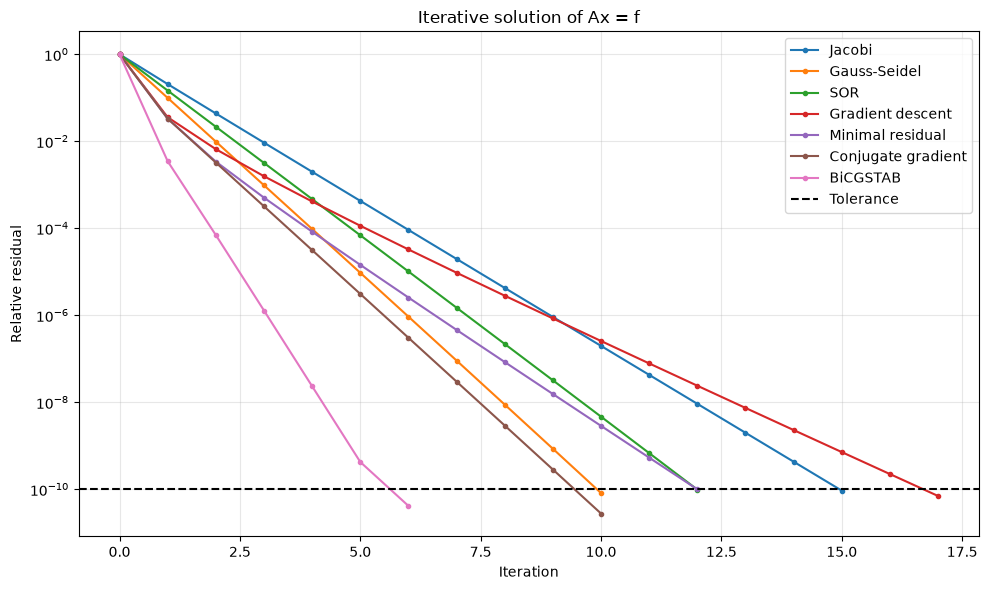

In [12]:
methods = [
    ("Gaussian elimination", gaussian_elimination),
    ("LU factorization", lu_factorization),
    ("Jacobi", jacobi),
    ("Gauss-Seidel", gauss_seidel),
    ("SOR", sor),
    ("Gradient descent", gradient_descent),
    ("Minimal residual", minimal_residual),
    ("Conjugate gradient", conjugate_gradient),
    ("BiCGSTAB", bicgstab),
]
solutions, histories, failures = {}, {}, {}
for name, solve in methods:
    try:
        if name in ("Gaussian elimination", "LU factorization"):
            x = solve(A, f)
        else:
            x, history = solve(A, f, omega) if name == "SOR" else solve(A, f)
            histories[name] = history
        if np.linalg.norm(f - A @ x) > threshold(f):
            raise ArithmeticError("The final residual exceeds the requested tolerance.")
        solutions[name] = x
        count = len(histories[name]) - 1 if name in histories else "direct"
        print(f"{name}: iterations={count}, residual={np.linalg.norm(f - A @ x):.3e}")
        print(np.array2string(x, precision=8))
    except (ValueError, ArithmeticError, RuntimeError) as error:
        failures[name] = str(error)
        print(f"{name}: {error}")

fig, ax = plt.subplots(figsize=(10, 6))
scale = np.linalg.norm(f) or 1.0
for name, history in histories.items():
    values = np.asarray(history) / scale
    label = name if name not in failures else f"{name} (failed)"
    ax.semilogy(np.where(values > 0, values, np.nan), marker=".", label=label)
ax.axhline(threshold(f) / scale, color="black", linestyle="--", label="Tolerance")
ax.set_xlabel("Iteration")
ax.set_ylabel("Relative residual" if np.linalg.norm(f) else "Absolute residual")
ax.set_title("Iterative solution of Ax = f")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

## 5. Проверка реализации

Для небольшой SPD-системы сравним все методы с контрольным решением NumPy.
Отдельно проверим перестановку строк у Гаусса, нулевую правую часть,
несимметричную систему для BiCGSTAB и эквивалентность SOR с параметром 1
методу Зейделя. Готовый решатель NumPy используется только здесь, для проверки.

In [13]:
test_A = np.array([[4.0, 1.0], [1.0, 3.0]])
test_f = np.array([1.0, 2.0])
expected = np.linalg.solve(test_A, test_f)
for name, solve in methods:
    if name in ("Gaussian elimination", "LU factorization"):
        actual = solve(test_A, test_f)
    else:
        actual, history = solve(test_A, test_f)
        assert history[-1] <= threshold(test_f)
        zero_x, zero_history = solve(test_A, np.zeros(2))
        np.testing.assert_array_equal(zero_x, np.zeros(2))
        assert len(zero_history) == 1
    np.testing.assert_allclose(actual, expected, atol=1e-9, rtol=1e-9)

pivot_A = np.array([[0.0, 1.0], [1.0, 2.0]])
np.testing.assert_allclose(gaussian_elimination(pivot_A, test_f), np.linalg.solve(pivot_A, test_f))
nonsymmetric_A = np.array([[4.0, 1.0], [2.0, 3.0]])
actual, _ = bicgstab(nonsymmetric_A, test_f)
np.testing.assert_allclose(actual, np.linalg.solve(nonsymmetric_A, test_f), atol=1e-9)
seidel_x, seidel_history = gauss_seidel(test_A, test_f)
sor_x, sor_history = sor(test_A, test_f, omega=1.0)
np.testing.assert_allclose(seidel_x, sor_x, atol=1e-14)
assert len(seidel_history) == len(sor_history)
# The supplied TXT example starts with comments and has a known solution.
example_A, example_f = read_system(materials / "system.txt")
np.testing.assert_allclose(gaussian_elimination(example_A, example_f), [1, 2, 3])
print("All nine solver checks passed.")

All nine solver checks passed.
